# Annotation quality scoring

Scores each AI-generated road annotation on how likely it is to need human correction, then ranks them so a reviewer with a limited budget checks the riskiest ones first. Built on one aerial scene (four tiles), comparing the raw U-Net output against the ground-truth layer, with the manual QA stage used as the answer key.

Outputs: `feature_scores.csv` (one row per annotation) and `cell_scores.csv` (one row per 50 m grid cell), both loaded into the team database.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q geopandas fiona

import zipfile, glob, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import fiona
from shapely.strtree import STRtree
from shapely.geometry import Point
warnings.filterwarnings('ignore')

OUT  = '/content/drive/MyDrive/capstone/'
ZIP  = OUT + 'training_samples_clipped-20260820T140114Z-1-001.zip'
DEST = '/content/data'

with zipfile.ZipFile(ZIP) as z:
    z.extractall(DEST)
gpkgs = sorted(glob.glob(DEST + '/**/*.gpkg', recursive=True))
print(len(gpkgs), 'geopackages found')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 64.9 MB/s eta 0:00:00
7 geopackages found


## 1. Profiling the data

The same scene appears at four stages: ground truth, raw AI output, the automatically cleaned output, and the output after manual QA. Before scoring anything, it is worth checking what each stage actually contains.

In [3]:
STAGES = {
    'gt':    'export_ready_fused_gt',
    'raw':   'export_ready_postfilter_fused',
    'clean': 'export_ready_postfilter_fused_clean',
    'qa':    'export_ready_postfilter_fused_manual_qa',
}

rows = []
for stage, folder in STAGES.items():
    for path in [p for p in gpkgs if f'/{folder}/' in p]:
        for layer in fiona.listlayers(path):
            g = gpd.read_file(path, layer=layer)
            rows.append({'stage': stage, 'layer': layer, 'n': len(g),
                         'geom': '|'.join(sorted(g.geom_type.dropna().unique())),
                         'crs': g.crs.to_string() if g.crs else None,
                         'invalid': int((~g.geometry.is_valid).sum()),
                         'cols': '|'.join(c for c in g.columns if c != 'geometry')})
prof = pd.DataFrame(rows)

drift = prof.pivot_table(index='layer', columns='stage', values='n', fill_value=0)[['gt','raw','clean','qa']]
print(drift.astype(int).to_string())

stage                        gt   raw  clean    qa
layer                                             
crossing_zone                32    97     97    12
intersection                 13    19     19    31
lane_centerline             243  1127    708   359
road_edge                    94   757    611   203
road_surface_markings         2     4      4   821
stop_line_outline            11     0      0    84
white_dashed_line_outline  1325  1738   1631  2763
white_line_outline           81  1607   1607   199
yellow_line_outline          11   202    150    23
zebra_zone                   28    41     41    69


In [4]:
keys = set()
for c in prof.cols:
    keys |= {x for x in c.split('|') if x.startswith('source')}
gt_layers  = set(prof.loc[prof.stage=='gt',  'layer'])
raw_layers = set(prof.loc[prof.stage=='raw', 'layer'])

print('tile id named as:      ', sorted(keys))
print('in GT, never predicted:', sorted(gt_layers - raw_layers))
print('CRS present:           ', sorted(prof.crs.dropna().unique()))
print('invalid geometries:    ', int(prof.invalid.sum()))

tile id named as:       ['source_image', 'source_til', 'source_tile']
in GT, never predicted: ['stop_line_outline']
CRS present:            ['EPSG:32653']
invalid geometries:     0


Three things come out of this. The tile identifier is named three different ways across stages, so joining on column name would silently return nothing. `stop_line_outline` exists in ground truth but the model never predicts it, which overlap-based scoring cannot detect. And the AI tends to over-produce: road edges go from 94 in ground truth to 757 in the raw output, largely because continuous lines come out fragmented.

## 2. Loading the stages

In [5]:
def load_stage(folder):
    out = {}
    for path in [p for p in gpkgs if f'/{folder}/' in p]:
        for layer in fiona.listlayers(path):
            out[layer] = gpd.read_file(path, layer=layer)
    return out

def tile_col(g):
    for k in ('source_tile', 'source_image', 'source_til'):
        if k in g.columns:
            return k
    return None

GT  = load_stage(STAGES['gt'])
RAW = load_stage(STAGES['raw'])
QA  = load_stage(STAGES['qa'])
print(sum(len(g) for g in RAW.values()), 'raw AI features across', len(RAW), 'classes')

5592 raw AI features across 9 classes


## 3. Agreement with ground truth

Each AI feature is compared with the best-overlapping ground-truth feature of the same class using IoU. Lines have no area, so both sides are buffered into 1 m corridors first.

Ground-truth coverage is not complete for every class. Crossings, for example, only have reference data on two of the four tiles, so an AI crossing on the other two tiles cannot be judged. Those features are marked `no_reference` rather than counted as wrong.

In [6]:
for layer, ai in RAW.items():
    g = GT.get(layer)
    gt_t = set(g[tile_col(g)].dropna()) if g is not None and tile_col(g) else set()
    ai_t = set(ai[tile_col(ai)].dropna()) if tile_col(ai) else set()
    gap = sorted(ai_t - gt_t)
    if gap:
        print(f'{layer:28s} GT on {len(gt_t)} of {len(ai_t)} tiles, uncovered: {gap}')

crossing_zone                GT on 2 of 4 tiles, uncovered: ['R_2025_06_27_0_1', 'R_2025_06_27_0_2']
zebra_zone                   GT on 3 of 4 tiles, uncovered: ['R_2025_06_27_1_2']
road_surface_markings        GT on 1 of 2 tiles, uncovered: ['R_2025_06_27_1_2']
yellow_line_outline          GT on 2 of 4 tiles, uncovered: ['R_2025_06_27_0_1', 'R_2025_06_27_0_2']


In [7]:
LINE_BUFFER = 1.0

def to_area(geom, buf=LINE_BUFFER):
    if geom.geom_type in ('LineString', 'MultiLineString'):
        return geom.buffer(buf)
    return geom if geom.is_valid else geom.buffer(0)

def agreement_for_layer(layer, ai, gt):
    ref  = [to_area(g) for g in gt.geometry] if gt is not None and len(gt) else []
    tree = STRtree(ref) if ref else None
    gcol = tile_col(gt) if gt is not None else None
    layer_tiles = set(gt[gcol].dropna()) if gcol else set()
    tcol = tile_col(ai)

    rows = []
    for i, row in ai.iterrows():
        tile  = row[tcol] if tcol else None
        probe = to_area(row.geometry)
        if tree is None or (tile is not None and tile not in layer_tiles):
            status, best = 'no_reference', np.nan
        else:
            best = 0.0
            for j in tree.query(probe):
                u = probe.union(ref[j]).area
                if u:
                    best = max(best, probe.intersection(ref[j]).area / u)
            status = 'matched' if best > 0 else 'unmatched'
        rows.append({'feature_id': f'{layer}:{i}', 'layer': layer, 'tile': tile,
                     'geom_type': row.geometry.geom_type,
                     'best_iou': best, 'match_status': status})
    return rows

feat = pd.DataFrame([r for layer, ai in RAW.items()
                     for r in agreement_for_layer(layer, ai, GT.get(layer))])
print(feat.match_status.value_counts().to_string())

match_status
matched         3248
unmatched       2236
no_reference     108


## 4. Continuity

The client asked specifically for broken lines to be detected. A first attempt flagged any line ending within 15 m of another line's endpoint, but that fired on 98% of lines, since road networks are made of segments that naturally end near each other. The distribution of endpoint gaps below has no clean cutoff, so instead each feature's largest gap is scored against its own class's distribution: gaps near the class median score close to 0, gaps in the top 5% close to 1. This also means a new class calibrates itself.

In [8]:
FRAG_LEN = 8.0   # metres; a line piece shorter than this counts as a fragment

def parts_of(geom):
    return list(geom.geoms) if geom.geom_type.startswith('Multi') else [geom]

def endpoints(geom):
    pts = []
    for p in parts_of(geom):
        if p.length > 0:
            c = list(p.coords)
            pts += [Point(c[0]), Point(c[-1])]
    return pts

def nearest_gaps(ai):
    ep, owner = [], []
    for i, row in ai.iterrows():
        for pt in endpoints(row.geometry):
            ep.append(pt); owner.append(i)
    tree = STRtree(ep)
    d = []
    for k, pt in enumerate(ep):
        cand = [pt.distance(ep[j]) for j in tree.query(pt.buffer(50)) if owner[j] != owner[k]]
        if cand:
            d.append(min(cand))
    return pd.Series(d)

for layer in ['lane_centerline', 'road_edge']:
    d = nearest_gaps(RAW[layer])
    print(f'{layer:16s} median gap {d.median():.1f} m | 90th pct {d.quantile(.9):.1f} m | over 15 m {(d>=15).mean():.1%}')

lane_centerline  median gap 1.1 m | 90th pct 6.5 m | over 15 m 2.1%
road_edge        median gap 3.6 m | 90th pct 11.8 m | over 15 m 5.5%


In [9]:
def continuity_for_layer(layer, ai):
    if ai.geom_type.iloc[0] not in ('LineString', 'MultiLineString'):
        return {f'{layer}:{i}': (0.0, 0.0) for i in ai.index}

    ep, owner = [], []
    for i, row in ai.iterrows():
        for pt in endpoints(row.geometry):
            ep.append(pt); owner.append(i)
    tree = STRtree(ep)

    worst = {}
    for k, pt in enumerate(ep):
        best = np.inf
        for j in tree.query(pt.buffer(60)):
            if owner[j] != owner[k]:
                best = min(best, pt.distance(ep[j]))
        if np.isfinite(best):
            worst[owner[k]] = max(worst.get(owner[k], 0.0), best)

    vals = pd.Series(list(worst.values()))
    lo, hi = vals.quantile(0.50), vals.quantile(0.95)
    span = max(hi - lo, 1e-6)

    out = {}
    for i, row in ai.iterrows():
        parts = parts_of(row.geometry)
        total = sum(p.length for p in parts)
        if total == 0:
            frag = 1.0
        else:
            short = sum(p.length for p in parts if p.length < FRAG_LEN)
            frag = 0.5 * ((len(parts) - 1) / max(len(parts), 1)) + 0.5 * (short / total)
        s_gap = float(np.clip((worst.get(i, 0.0) - lo) / span, 0, 1))
        out[f'{layer}:{i}'] = (round(min(frag, 1.0), 4), round(s_gap, 4))
    return out

cont = {}
for layer, ai in RAW.items():
    cont.update(continuity_for_layer(layer, ai))

feat['s_fragment']   = feat.feature_id.map(lambda k: cont[k][0])
feat['s_gap']        = feat.feature_id.map(lambda k: cont[k][1])
feat['s_continuity'] = (0.5 * feat.s_fragment + 0.5 * feat.s_gap).round(4)
print(feat[feat.geom_type.str.contains('Line')].groupby('layer')[['s_fragment','s_gap','s_continuity']].agg(['mean','std']).round(3).to_string())

                s_fragment         s_gap        s_continuity       
                      mean    std   mean    std         mean    std
layer                                                              
lane_centerline      0.235  0.249  0.162  0.279        0.198  0.167
road_edge            0.206  0.246  0.193  0.294        0.200  0.174


## 5. Geometry validity, and why the model's `score` is not used

The raw output carries a `score` column that looks like model confidence. It is not: every feature in a class has exactly the same value, so it is a per-class detection threshold and cannot tell a good feature from a bad one within its class. It is left out of the scoring.

In [10]:
print('distinct score values per class:',
      {l: g.score.nunique() for l, g in RAW.items() if 'score' in g.columns})

def geom_signal(g):
    if g is None or g.is_empty or not g.is_valid:
        return 1.0
    m = g.length if g.geom_type in ('LineString', 'MultiLineString') else g.area
    return 1.0 if m <= 0 else 0.0

gflag = {f'{layer}:{i}': geom_signal(g) for layer, ai in RAW.items() for i, g in ai.geometry.items()}
feat['s_geometry'] = feat.feature_id.map(gflag)
print('invalid or degenerate geometries:', int(feat.s_geometry.sum()))

distinct score values per class: {'lane_centerline': 1, 'road_edge': 1, 'crossing_zone': 1, 'zebra_zone': 1, 'intersection': 1, 'road_surface_markings': 1, 'white_line_outline': 1, 'white_dashed_line_outline': 1, 'yellow_line_outline': 1}
invalid or degenerate geometries: 0


## 6. The answer key: what a human corrected

To test whether a ranking works, we need to know which features were actually bad. The manual QA stage provides that independently of the scoring: if nothing similar to a raw AI feature survived into QA (IoU below 0.3), a human removed or heavily changed it.

In [11]:
MATCH_IOU = 0.30

def survived_qa(layer, ai, qa):
    if qa is None or len(qa) == 0:
        return {f'{layer}:{i}': 0 for i in ai.index}
    ref  = [to_area(g) for g in qa.geometry]
    tree = STRtree(ref)
    out = {}
    for i, row in ai.iterrows():
        probe = to_area(row.geometry)
        best = 0.0
        for j in tree.query(probe):
            u = probe.union(ref[j]).area
            if u:
                best = max(best, probe.intersection(ref[j]).area / u)
        out[f'{layer}:{i}'] = int(best >= MATCH_IOU)
    return out

surv = {}
for layer, ai in RAW.items():
    surv.update(survived_qa(layer, ai, QA.get(layer)))
feat['needed_correction'] = 1 - feat.feature_id.map(surv)

base = feat.needed_correction.mean()
print(f'{base:.1%} of raw AI features needed correction')
print(f'best possible lift at this base rate: {1/base:.2f}x')

67.8% of raw AI features needed correction
best possible lift at this base rate: 1.48x


## 7. Rule-based baseline

A weighted sum of the signals with hand-picked weights. Features without reference data are scored only on the signals available to them.

In [12]:
feat['s_agree']     = np.where(feat.match_status == 'no_reference', np.nan, 1.0 - feat.best_iou.fillna(0))
feat['s_unmatched'] = np.where(feat.match_status == 'unmatched', 1.0,
                      np.where(feat.match_status == 'matched', 0.0, np.nan))

W = {'s_agree': 0.40, 's_unmatched': 0.28, 's_continuity': 0.22, 's_geometry': 0.10}
num = sum(W[k] * feat[k].fillna(0) for k in W)
den = sum(W[k] * feat[k].notna()    for k in W)
feat['risk_score'] = (num / den).round(4)
feat = feat.sort_values('risk_score', ascending=False).reset_index(drop=True)

n = len(feat)
for fr in (0.05, 0.10, 0.20):
    p = feat.head(int(fr * n)).needed_correction.mean()
    print(f'top {fr:>4.0%}: {p:.1%} needed correction  ->  {p/base:.2f}x random')

top   5%: 91.8% needed correction  ->  1.35x random
top  10%: 92.1% needed correction  ->  1.36x random
top  20%: 92.2% needed correction  ->  1.36x random


## 8. Assigning grid cells

The database and dashboard work in 50 m grid cells. Each feature is placed in a cell by its centroid, using the tile origin from the database schema.

In [13]:
CELL = 50.0
MINX, MINY = 535754.411673001, 3834235.415406951

cent = {f'{layer}:{i}': g.centroid for layer, ai in RAW.items() for i, g in ai.geometry.items()}
feat['cell_id'] = feat.feature_id.map(lambda k: f'r{int((cent[k].y - MINY)//CELL)}c{int((cent[k].x - MINX)//CELL)}')

sizes = feat.groupby('cell_id').size()
print(f'{feat.cell_id.nunique()} occupied cells, {sizes.mean():.1f} features per cell on average')

227 occupied cells, 24.6 features per cell on average


## 9. Training the scoring function

Rather than hand-picking weights, a model learns them from the QA outcomes. To avoid it memorising locations, training is leave-one-tile-out: each tile is scored by a model that never saw it.

No class names are used as inputs, so a new class does not break anything. Class information enters only as a learned prior, the correction rate of that class in the training tiles, and an unseen class falls back to the overall average.

In [14]:
size, is_lin = {}, {}
for layer, ai in RAW.items():
    for i, g in ai.geometry.items():
        lin = g.geom_type in ('LineString', 'MultiLineString')
        is_lin[f'{layer}:{i}'] = int(lin)
        size[f'{layer}:{i}']   = g.length if lin else g.area

feat['is_linear']   = feat.feature_id.map(is_lin)
feat['log_size']    = np.log1p(feat.feature_id.map(size))
feat['size_pctile'] = feat.groupby('layer').log_size.rank(pct=True)
feat['cell_n']      = feat.groupby('cell_id').feature_id.transform('size')

FEATURES = ['s_agree','s_unmatched','s_continuity','s_fragment','s_gap','s_geometry',
            'is_linear','log_size','size_pctile','cell_n','class_prior']

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

tiles = sorted(feat.tile.dropna().unique())
y = feat.needed_correction.values

def class_prior(train_idx):
    tr = feat.iloc[train_idx]
    return feat.layer.map(tr.groupby('layer').needed_correction.mean()).fillna(tr.needed_correction.mean()).values

oof = {m: np.full(n, np.nan) for m in ['rule', 'logreg', 'gbm']}
for t in tiles:
    te = np.where(feat.tile == t)[0]
    tr = np.where(feat.tile != t)[0]
    feat['class_prior'] = class_prior(tr)
    X   = feat[FEATURES].fillna(0.5).values

    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced'))
    oof['logreg'][te] = lr.fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]

    gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, max_depth=4, random_state=0)
    oof['gbm'][te] = gb.fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]

    oof['rule'][te] = feat.risk_score.values[te]

def lift_at(scores, frac):
    k = max(1, int(frac * n))
    return y[np.argsort(-scores)[:k]].mean() / y.mean()

print(f'{"model":14s} {"@5%":>7} {"@10%":>7} {"@20%":>7}')
for m in oof:
    print(f'{m:14s} ' + ' '.join(f'{lift_at(oof[m], f):>6.2f}x' for f in (0.05, 0.10, 0.20)))
print(f'{"ceiling":14s} {1/base:>6.2f}x')

model              @5%    @10%    @20%
rule             1.35x   1.34x   1.16x
logreg           1.40x   1.40x   1.41x
gbm              1.44x   1.45x   1.44x
ceiling          1.48x


Gradient boosting comes out best, at roughly 97% of the ceiling.

Holding out tiles does not test a new class, since every class still appears in training. The cell below holds out one class at a time and scores it with a model that has never seen it, without the class prior, which is the situation if the client adds something like traffic islands.

In [16]:
from sklearn.metrics import roc_auc_score

Xnc = feat[[f for f in FEATURES if f != 'class_prior']].fillna(0.5).values
oof['unseen_class'] = np.full(n, np.nan)
for c in sorted(feat.layer.unique()):
    te = np.where(feat.layer == c)[0]
    tr = np.where(feat.layer != c)[0]
    gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, max_depth=4, random_state=0)
    oof['unseen_class'][te] = gb.fit(Xnc[tr], y[tr]).predict_proba(Xnc[te])[:, 1]
    yy = y[te]
    auc = roc_auc_score(yy, oof['unseen_class'][te]) if 0 < yy.mean() < 1 else np.nan
    print(f'{c:28s} n={len(te):5d}  within-class AUC {auc:.2f}')

print(f'\nunseen-class lift at 5%: {lift_at(oof["unseen_class"], .05):.2f}x')

crossing_zone                n=   97  within-class AUC 0.70
intersection                 n=   19  within-class AUC 0.91
lane_centerline              n= 1127  within-class AUC 0.90
road_edge                    n=  757  within-class AUC 0.87
road_surface_markings        n=    4  within-class AUC nan
white_dashed_line_outline    n= 1738  within-class AUC 0.60
white_line_outline           n= 1607  within-class AUC 0.52
yellow_line_outline          n=  202  within-class AUC 0.63
zebra_zone                   n=   41  within-class AUC 0.81

unseen-class lift at 5%: 1.23x


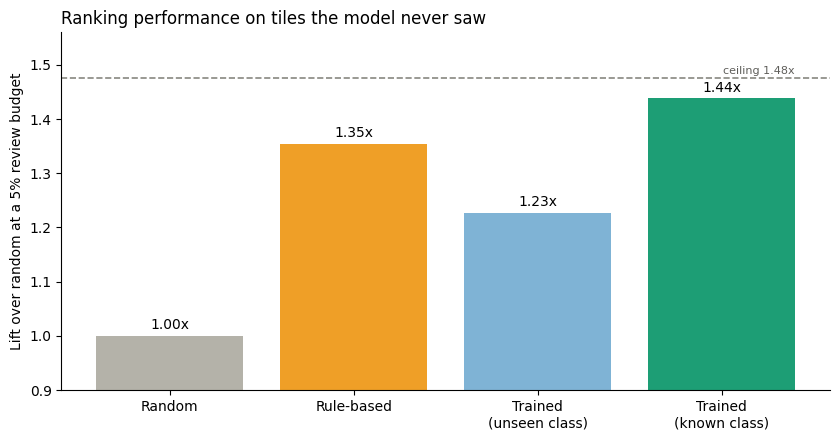

In [17]:
import matplotlib.pyplot as plt

labels = ['Random', 'Rule-based', 'Trained\n(unseen class)', 'Trained\n(known class)']
vals   = [1.0, lift_at(oof['rule'], .05), lift_at(oof['unseen_class'], .05), lift_at(oof['gbm'], .05)]
cols   = ['#b4b2a9', '#ef9f27', '#7fb3d5', '#1d9e75']

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(labels, vals, color=cols)
ax.axhline(1/base, ls='--', lw=1.2, color='#888780')
ax.text(3.4, 1/base + 0.008, f'ceiling {1/base:.2f}x', fontsize=8, color='#5f5e5a', ha='right')
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.012, f'{v:.2f}x', ha='center', fontsize=10)
ax.set_ylabel('Lift over random at a 5% review budget')
ax.set_title('Ranking performance on tiles the model never saw', loc='left', fontsize=12)
ax.set_ylim(0.9, 1.56); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(OUT + 'chart_models.png', dpi=160); plt.show()

## 10. Final scores and export

The trained model's out-of-fold scores become `model_score`, with the rule-based score kept alongside as `baseline_score`. Scores are then rolled up to cells.

The database originally used a yes/no `needs_review` target per cell, true if any feature in the cell needed correction. With around 25 features per cell that is true almost everywhere, so the cell table carries the correction rate instead. `expected_bad` (model score × feature count) is included for ranking cells when the review budget is counted in cells rather than annotations.

In [18]:
feat['model_score']    = oof['gbm']
feat['baseline_score'] = feat.risk_score
feat['quality_score']  = (100 * (1 - feat.model_score)).round(1)
feat = feat.sort_values('model_score', ascending=False).reset_index(drop=True)

cells = (feat.groupby('cell_id')
    .agg(n_features=('feature_id', 'size'),
         mean_quality=('quality_score', 'mean'),
         baseline_score=('baseline_score', 'mean'),
         model_score=('model_score', 'mean'),
         n_unmatched=('s_unmatched', 'sum'),
         correction_rate=('needed_correction', 'mean'),
         any_correction=('needed_correction', 'max'))
    .round(4).reset_index())
cells['cell_risk']    = (100 - cells.mean_quality).round(1)
cells = cells.sort_values('model_score', ascending=False).reset_index(drop=True)
cells['rank']         = range(1, len(cells) + 1)
cells['expected_bad'] = (cells.model_score * cells.n_features).round(3)

print(f'cells where any feature needed correction: {cells.any_correction.mean():.1%}')
print(f'correction rate across cells: mean {cells.correction_rate.mean():.2f}, sd {cells.correction_rate.std():.2f}')

cells where any feature needed correction: 96.9%
correction rate across cells: mean 0.69, sd 0.25


In [19]:
# row_id links each feature to the features table in the database
m = pd.read_csv(OUT + 'standardised_features.csv', usecols=['feature_id', 'stage', 'standardised_class'])
m = m[m.stage == 'raw_ai'].copy()
m['row_id'] = m.feature_id.str.rsplit(':', n=1).str[-1].astype(int)
m = m.sort_values('row_id')
m['feature_id'] = m.standardised_class + ':' + m.groupby('standardised_class').cumcount().astype(str)
feat['row_id'] = feat.feature_id.map(m.set_index('feature_id').row_id)
assert feat.row_id.notna().all()

KEEP = ['row_id','feature_id','layer','cell_id','tile','geom_type','match_status','best_iou',
        's_agree','s_unmatched','s_continuity','s_fragment','s_gap','s_geometry',
        'baseline_score','model_score','quality_score','needed_correction']
feat[KEEP].to_csv(OUT + 'feature_scores.csv', index=False)
cells.to_csv(OUT + 'cell_scores.csv', index=False)
print(f'feature_scores.csv: {len(feat)} rows | cell_scores.csv: {len(cells)} rows')

feature_scores.csv: 5592 rows | cell_scores.csv: 227 rows
